In [20]:
import pandas as pd

pd.set_option("display.max_columns", None)   # show all columns

device_exposure = pd.read_csv("data/Device_exposure_per_visit.csv")
measurements = pd.read_csv("data/Measurements_per_visit.csv")

In [21]:
print(device_exposure.head())

   visit_occurrence_id  device_exposure_id device_exposure_start_datetime device_exposure_end_datetime  duur_uren
0                    5          1437661717        2013-01-01 00:48:00 UTC      2013-01-02 20:22:00 UTC         43
1                   11          1437661769        2006-01-01 01:04:00 UTC      2006-01-02 12:54:00 UTC         35
2                   15          1437661808        2013-01-01 01:53:00 UTC      2013-01-03 18:32:00 UTC         64
3                   15          1437661810        2013-01-03 18:38:00 UTC      2013-01-10 20:40:00 UTC        170
4                   18          1437661830        2013-01-01 00:03:00 UTC      2013-01-01 07:33:00 UTC          7


In [22]:
print(measurements.head())

   visit_occurrence_id  dag_nr       datum  uur                uur_start  n_metingen  m_3024882  m_3025408  m_3014080  m_40762499  m_3022875  m_21490855  m_3016078  m_42527086  m_3000461  m_42527137  m_3007469  \
0                 4587      29  2006-01-29   12  2006-01-29 12:00:00 UTC          21      40.00      40.00        NaN         NaN       6.00        6.00      15.00        8.00       8.00         NaN        NaN   
1                 4587      29  2006-01-29   13  2006-01-29 13:00:00 UTC          23      40.00      40.00        NaN       97.00       6.00        6.00      15.00        9.00       8.00         NaN        NaN   
2                 4587      29  2006-01-29   14  2006-01-29 14:00:00 UTC          31      40.00      40.00        NaN         NaN       6.00        6.00      14.00        9.00       8.00         NaN        NaN   
3                 4587      29  2006-01-29   15  2006-01-29 15:00:00 UTC          23      40.00      40.00        NaN       97.50       6.00        

Numeric features: 44 | Categorical features: 6
Measurements: (1190534, 56) | Device exposure: (6768, 5)
Visits in measurements: 5260
Visits in device_exposure: 5260
Duplicate (visit, hour) rows: 0

Hours per visit:
 count   5,260.00
mean      226.34
std       286.65
min         3.00
25%        49.00
50%       120.00
75%       285.00
max     3,184.00
dtype: float64

Device duration (hours):
 count   6,768.00
mean      126.86
std       165.55
min         4.00
25%        21.00
50%        65.00
75%       168.00
max     1,825.00
Name: duur_uren, dtype: float64

Device rows per visit:
 count   5,260.00
mean        1.29
std         0.69
min         1.00
25%         1.00
50%         1.00
75%         1.00
max         7.00
dtype: float64

Gap between consecutive rows (hours):
 uur_start
1.00     1074416
2.00       81510
3.00        6507
4.00        4335
5.00        3023
6.00        1729
24.00       1629
7.00        1164
8.00        1115
9.00         926
Name: count, dtype: int64

               

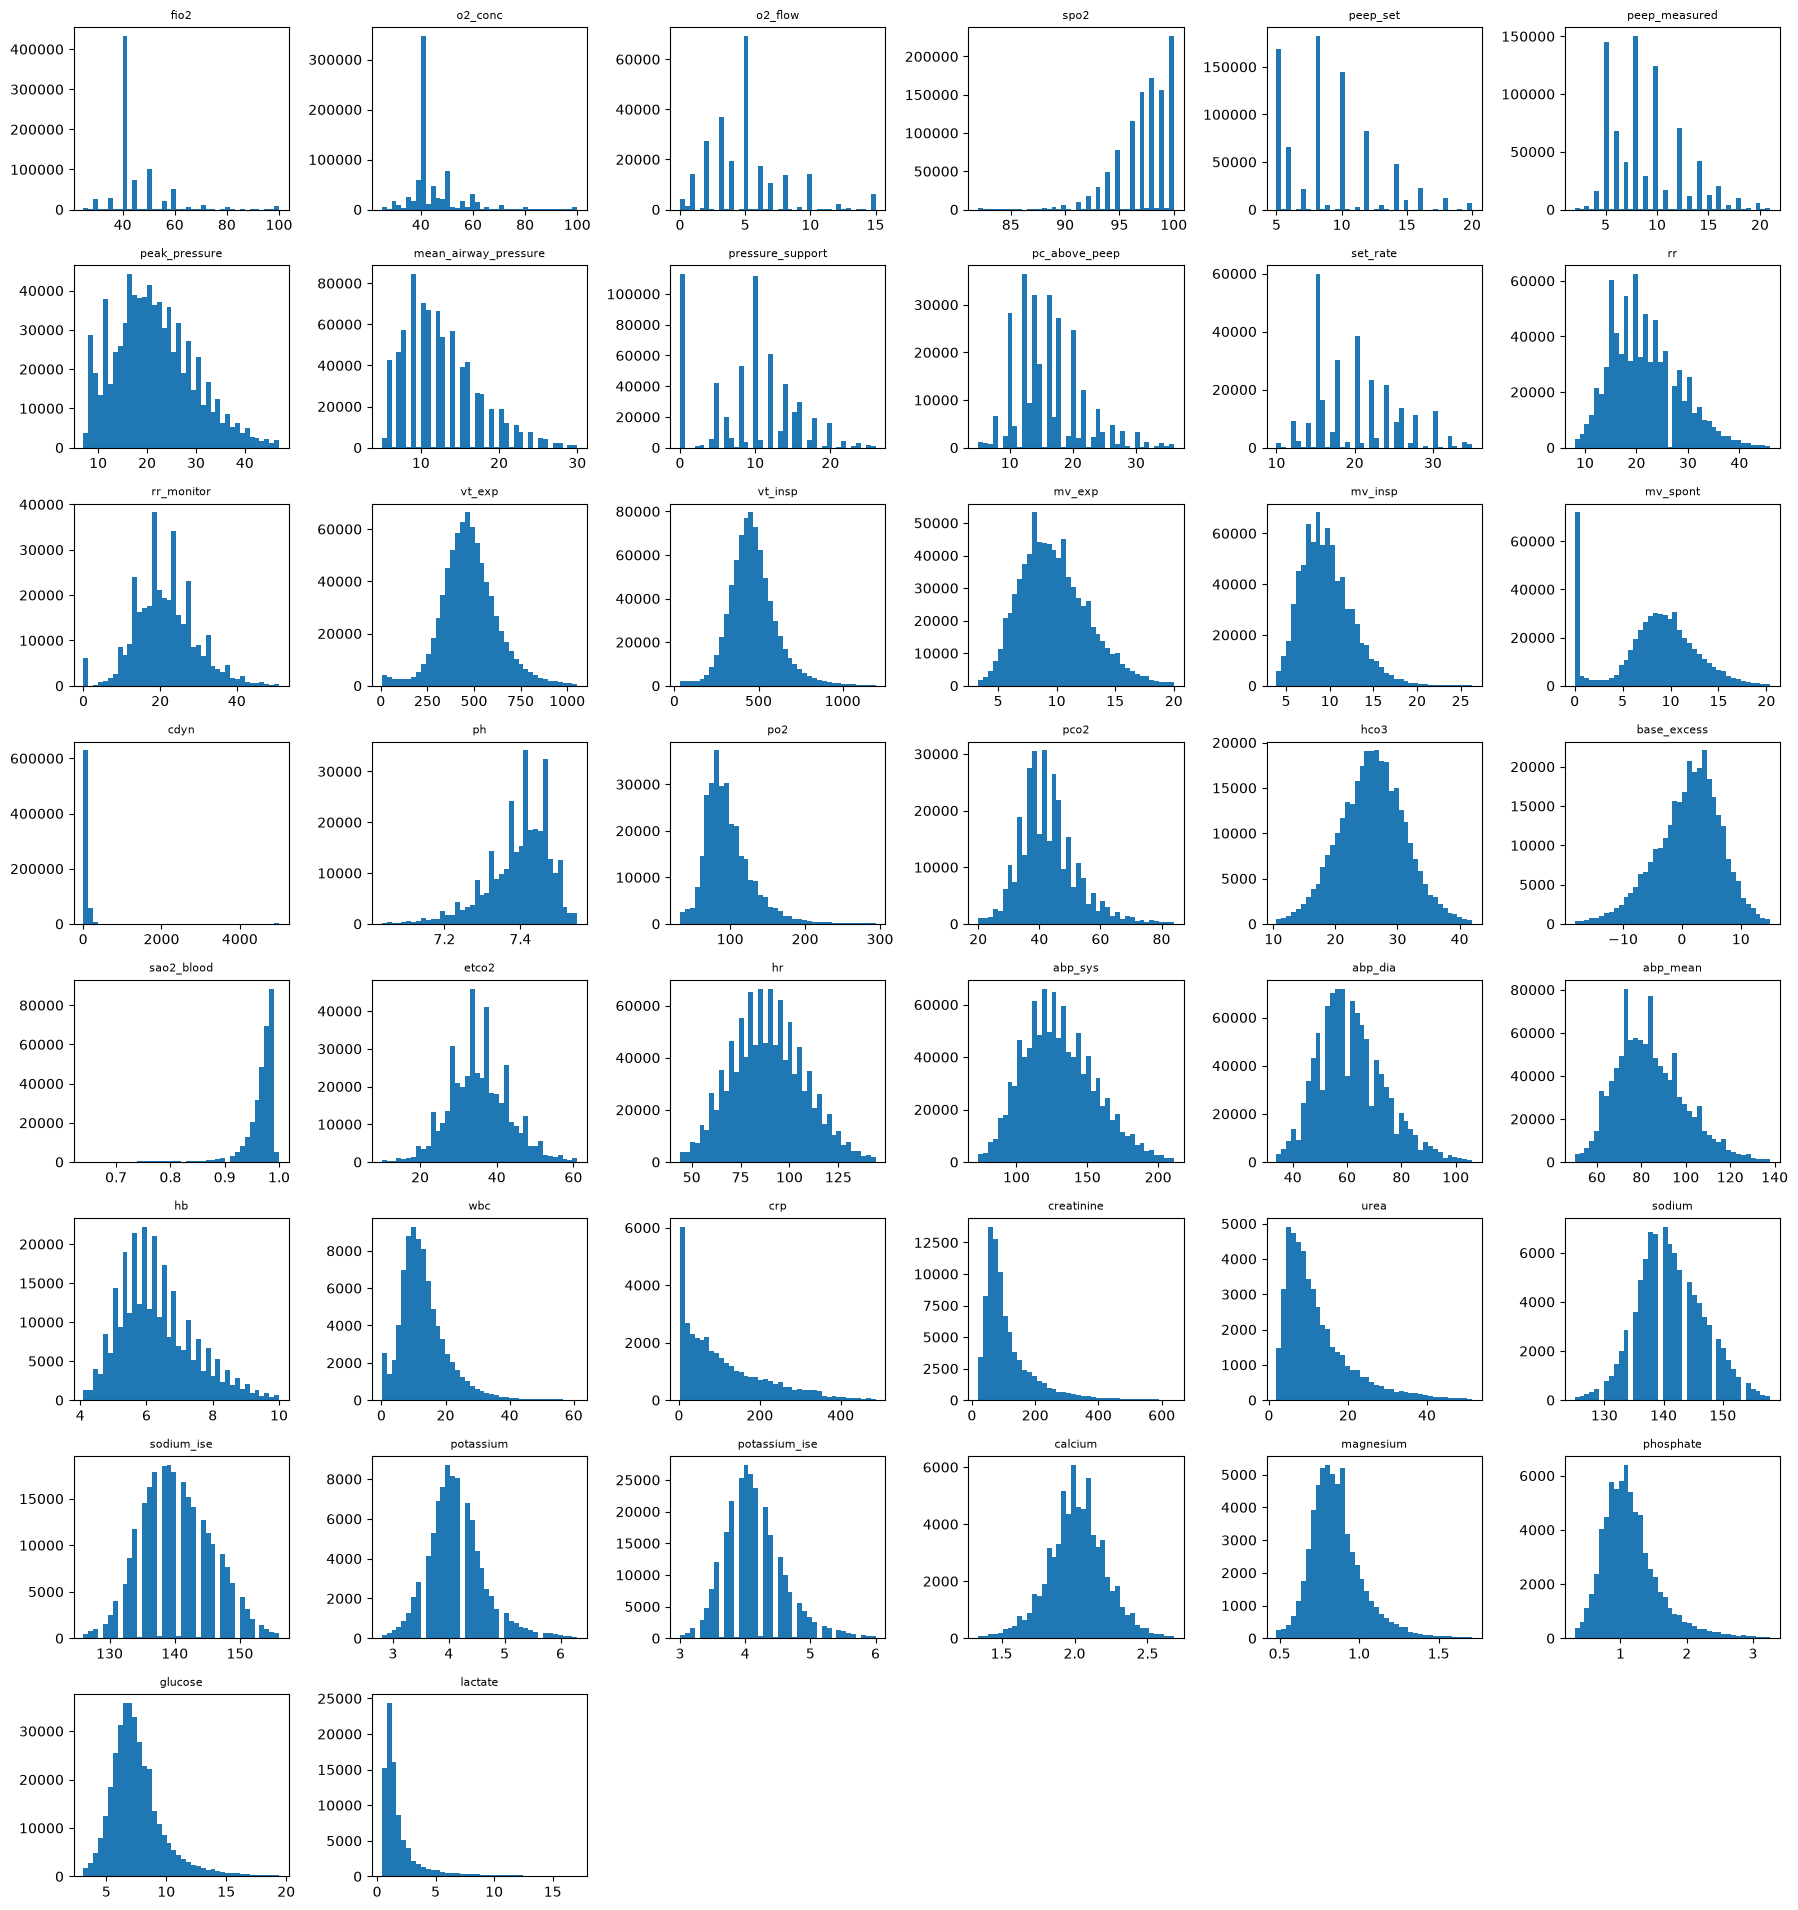

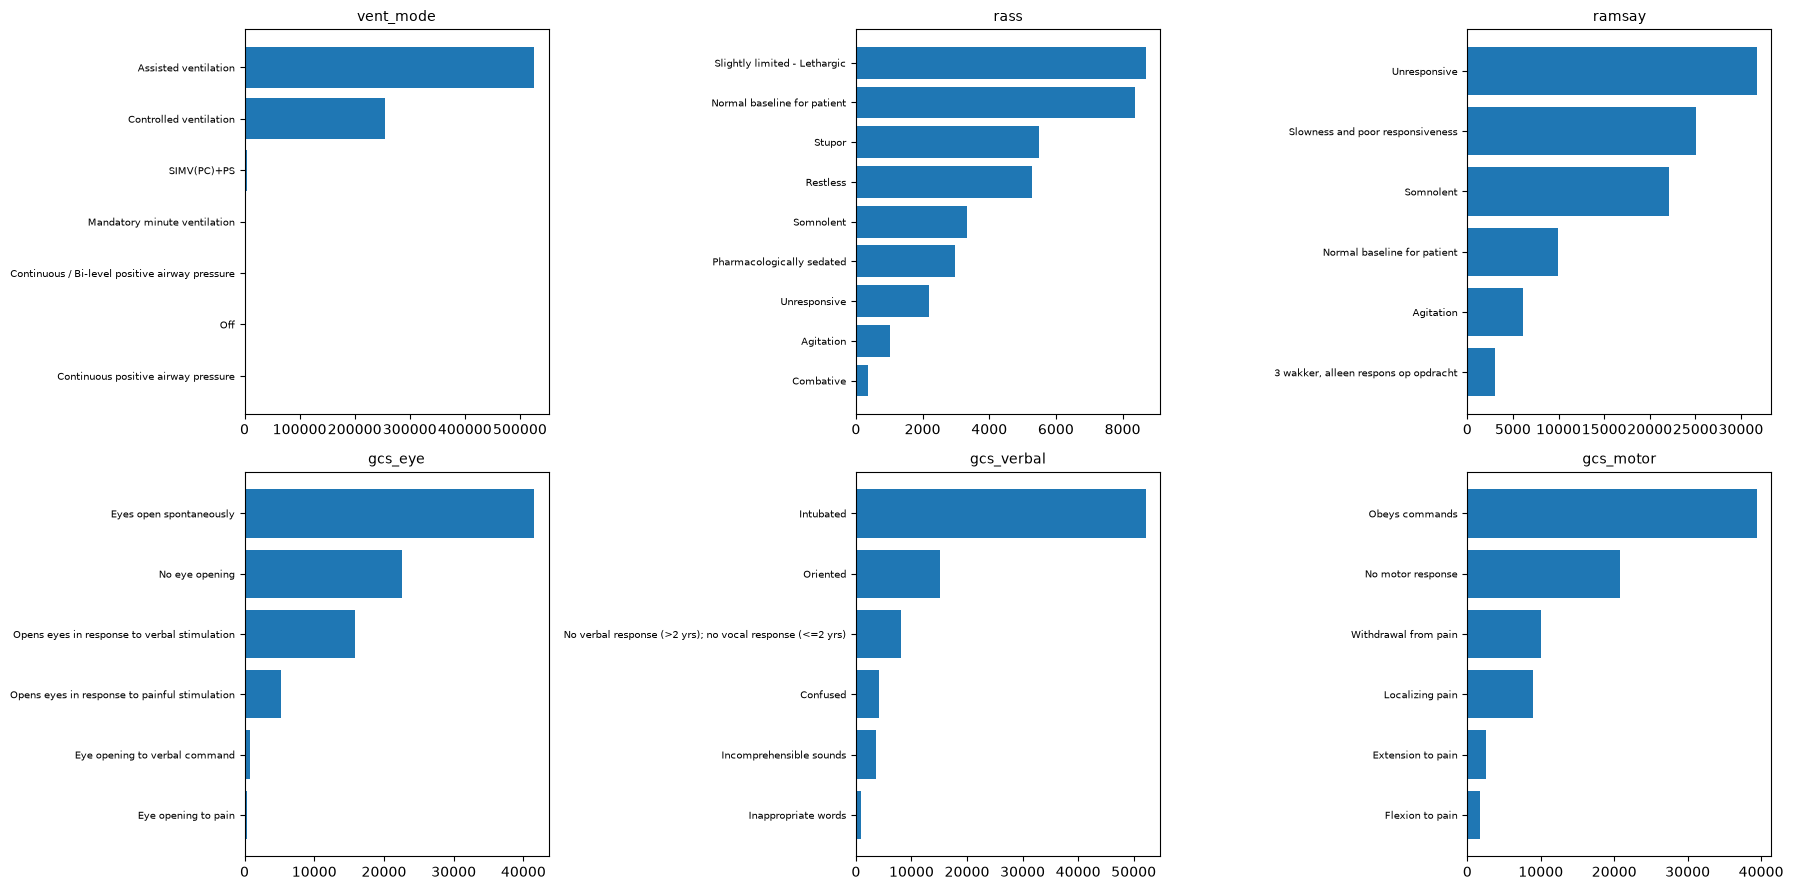

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# 2. Readable feature names
names = {
    3024882: "fio2", 3025408: "o2_conc", 3014080: "o2_flow", 40762499: "spo2",
    3022875: "peep_set", 21490855: "peep_measured", 3016078: "peak_pressure",
    42527086: "mean_airway_pressure", 3000461: "pressure_support", 42527137: "pc_above_peep",
    3007469: "set_rate", 3007646: "rr", 3024171: "rr_monitor", 3015016: "vt_exp",
    3016166: "vt_insp", 42527120: "mv_exp", 42527121: "mv_insp", 4108000: "mv_spont",
    3004921: "vent_mode", 21490582: "cdyn", 3010421: "ph", 3027315: "po2",
    3013290: "pco2", 3006576: "hco3", 3012501: "base_excess", 42869608: "sao2_blood",
    3035357: "etco2", 21490872: "hr", 21490853: "abp_sys", 21490851: "abp_dia",
    21490852: "abp_mean", 40762351: "hb", 3010813: "wbc", 3020460: "crp",
    3020564: "creatinine", 43534077: "urea", 3019550: "sodium", 3000285: "sodium_ise",
    3023103: "potassium", 3005456: "potassium_ise", 3015377: "calcium",
    3012095: "magnesium", 3003458: "phosphate", 3020491: "glucose", 3047181: "lactate",
    36684829: "rass", 4105091: "ramsay", 3016335: "gcs_eye", 3009094: "gcs_verbal",
    3008223: "gcs_motor",
}
categorical_ids = [3004921, 36684829, 4105091, 3016335, 3009094, 3008223]
numeric_ids = [k for k in names if k not in categorical_ids]

# drop the old (always empty) numeric columns of the categorical items, if still present
measurements = measurements.drop(
    columns=[f"m_{k}" for k in categorical_ids if f"m_{k}" in measurements.columns]
)

rename_map = {f"m_{k}": names[k] for k in numeric_ids}
rename_map.update({f"c_{k}": names[k] for k in categorical_ids})
measurements = measurements.rename(columns=rename_map)

numeric_features = [names[k] for k in numeric_ids if names[k] in measurements.columns]
categorical_features = [names[k] for k in categorical_ids if names[k] in measurements.columns]
print("Numeric features:", len(numeric_features), "| Categorical features:", len(categorical_features))

# clean up the text of the categorical columns
for c in categorical_features:
    measurements[c] = measurements[c].astype("string").str.strip()

# 3. Types, sorting, structure checks
measurements["uur_start"] = pd.to_datetime(measurements["uur_start"])
measurements = measurements.sort_values(["visit_occurrence_id", "uur_start"]).reset_index(drop=True)
for col in ["device_exposure_start_datetime", "device_exposure_end_datetime"]:
    device_exposure[col] = pd.to_datetime(device_exposure[col])

print("Measurements:", measurements.shape, "| Device exposure:", device_exposure.shape)
print("Visits in measurements:", measurements["visit_occurrence_id"].nunique())
print("Visits in device_exposure:", device_exposure["visit_occurrence_id"].nunique())
print("Duplicate (visit, hour) rows:",
      measurements.duplicated(["visit_occurrence_id", "uur_start"]).sum())

print("\nHours per visit:\n", measurements.groupby("visit_occurrence_id").size().describe())
print("\nDevice duration (hours):\n", device_exposure["duur_uren"].describe())
print("\nDevice rows per visit:\n", device_exposure.groupby("visit_occurrence_id").size().describe())

gap_h = measurements.groupby("visit_occurrence_id")["uur_start"].diff().dt.total_seconds() / 3600
print("\nGap between consecutive rows (hours):\n", gap_h.value_counts().head(10))

# 4a. Numeric features: min, max, percentiles, outliers
num = measurements[numeric_features].apply(pd.to_numeric, errors="coerce")

q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
n_out = (num.lt(q1 - 1.5 * iqr) | num.gt(q3 + 1.5 * iqr)).sum()

summary = pd.DataFrame({
    "n": num.count(),
    "pct_missing": num.isna().mean() * 100,
    "min": num.min(), "p1": num.quantile(0.01), "median": num.median(),
    "mean": num.mean(), "p99": num.quantile(0.99), "max": num.max(), "std": num.std(),
    "n_negative": num.lt(0).sum(), "n_zero": num.eq(0).sum(),
    "n_outliers_iqr": n_out, "pct_outliers_iqr": n_out / num.count() * 100,
})
print("\n", summary.sort_values("pct_missing"))
summary.to_csv("data/feature_summary.csv")

# 4b. Categorical features: missingness, unique values, value counts
cat_summary = pd.DataFrame({
    "n": [measurements[c].notna().sum() for c in categorical_features],
    "pct_missing": [measurements[c].isna().mean() * 100 for c in categorical_features],
    "n_unique": [measurements[c].nunique() for c in categorical_features],
    "top_value": [measurements[c].value_counts().index[0] if measurements[c].notna().any() else None
                  for c in categorical_features],
    "top_share_pct": [measurements[c].value_counts(normalize=True).iloc[0] * 100
                      if measurements[c].notna().any() else np.nan for c in categorical_features],
}, index=categorical_features)
print("\nCategorical summary:\n", cat_summary)
cat_summary.to_csv("data/categorical_summary.csv")

for c in categorical_features:
    print(f"\n--- {c} ---")
    print(measurements[c].value_counts(dropna=False).head(20))

# 5a. Histograms (numeric), without the 0.5% most extreme values on each side
cols = list(num.columns)
n_cols = 6
n_rows = int(np.ceil(len(cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 2.4 * n_rows))
for ax, c in zip(axes.ravel(), cols):
    s = num[c].dropna()
    if len(s):
        lo, hi = s.quantile([0.005, 0.995])
        ax.hist(s[(s >= lo) & (s <= hi)], bins=40)
    ax.set_title(c, fontsize=8)
for ax in axes.ravel()[len(cols):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("data/histograms.png", dpi=120)
plt.show()

# 5b. Bar charts (categorical): the 12 most frequent values per feature
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(), categorical_features):
    vc = measurements[c].value_counts().head(12)
    ax.barh(vc.index.astype(str)[::-1], vc.values[::-1])
    ax.set_title(c, fontsize=10)
    ax.tick_params(axis="y", labelsize=7)
for ax in axes.ravel()[len(categorical_features):]:
    ax.axis("off")
plt.tight_layout()
plt.savefig("data/categorical_counts.png", dpi=120)
plt.show()